# Natural Language Processing — Lab 05
## N-gram Language Models & Smoothing

| | |
|---|---|
| **Student** | Eman Amjad |
| **Roll Number** | FA23-BAI-013 |
| **Course** | Natural Language Processing |

Bigram and trigram language models built with `nltk.lm`, sentence probability and perplexity,
the zero-probability problem of unsmoothed counting, and five smoothing methods (MLE, Laplace,
Add-k, Kneser-Ney, Witten-Bell) compared by perplexity on movie and product review text.

In [1]:
# Setup  |  Eman Amjad  |  FA23-BAI-013
import math
import random
from pathlib import Path

import nltk
import pandas as pd
import matplotlib.pyplot as plt

for pkg in ["punkt", "punkt_tab", "movie_reviews", "product_reviews_1"]:
    nltk.download(pkg, quiet=True)

from nltk.tokenize import word_tokenize
from nltk.lm.preprocessing import padded_everygram_pipeline, pad_both_ends, flatten
from nltk.util import ngrams
from nltk.lm import (MLE, Laplace, Lidstone, KneserNeyInterpolated,
                     WittenBellInterpolated, Vocabulary)

DATA = Path("data/lab05")
DATA.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 120)
print("nltk", nltk.__version__)

nltk 3.10.4


### Preparing the two corpora

The manual reads `movie_corpus.txt` (one movie-review sentence per line) and a
`product_reviews_corpus`. Neither file came with the manual, so both are built from real
review text shipped with NLTK:

* **movie_corpus.txt** — 800 sentences sampled (fixed seed) from the Pang & Lee `movie_reviews`
  corpus. A few sentences containing the words the activities ask about (*fantastic, acting,
  convincing, disappointing, wonderful, quite, film*) are always included, so the held-out
  sentences can be scored without out-of-vocabulary noise.
* **product_reviews_corpus.txt** — every sentence of the Hu & Liu `product_reviews_1` corpus
  (customer reviews of two digital cameras, a phone, an MP3 player and a DVD player).

In [2]:
# Data preparation  |  Eman Amjad  |  FA23-BAI-013
from nltk.corpus import movie_reviews, product_reviews_1

rng = random.Random(13)
movie_sents = [s for s in movie_reviews.sents() if 6 <= len(s) <= 25]

# guarantee a few examples of the words the activities score, then fill up randomly
anchors = ["fantastic", "convincing", "acting", "disappointing", "wonderful", "quite", "film"]
chosen = set()
for word in anchors:
    pool = [i for i, s in enumerate(movie_sents) if word in s]
    rng.shuffle(pool)
    chosen.update(pool[:4])
order = list(range(len(movie_sents)))
rng.shuffle(order)
for i in order:
    if len(chosen) >= 800:
        break
    chosen.add(i)

movie_lines = [" ".join(movie_sents[i]) for i in sorted(chosen)]
(DATA / "movie_corpus.txt").write_text("\n".join(movie_lines) + "\n", encoding="utf-8")

product_lines = [" ".join(s) for s in product_reviews_1.sents()]
(DATA / "product_reviews_corpus.txt").write_text("\n".join(product_lines) + "\n", encoding="utf-8")

for name in ["movie_corpus.txt", "product_reviews_corpus.txt"]:
    lines = (DATA / name).read_text(encoding="utf-8").splitlines()
    print(f"{name:28s} {len(lines):5d} sentences   e.g. {lines[3][:70]!r}")

movie_corpus.txt               800 sentences   e.g. 'and , as we know , the movie was a smashing success at the box office '
product_reviews_corpus.txt    3947 sentences   e.g. 'before you try to return the player or waste hours calling apex tech s'


---
# In-Lab Activities

**Activity 1** — Using the movie_corpus dataset, build a bigram language model with `nltk.lm`
(no smoothing). Compute the probability and perplexity of the held-out sentence under this model,
and report where the model assigns zero probability.

In [3]:
# Activity 1  |  Eman Amjad  |  FA23-BAI-013
with open(DATA / "movie_corpus.txt", "r", encoding="utf-8") as f:
    corpus = [line.strip().lower() for line in f if line.strip()]
tokenized_corpus = [word_tokenize(sentence) for sentence in corpus]

# lowercase the held-out sentence the same way as the training text,
# otherwise capital letters would create fake out-of-vocabulary words
held_out = "the movie was fantastic and the acting was convincing"
assert held_out not in corpus
tokenized_held_out = word_tokenize(held_out.lower())

print(f"Training sentences: {len(tokenized_corpus)}, tokens: {sum(map(len, tokenized_corpus))}")

# padded_everygram_pipeline returns one-shot generators, so it is rebuilt for every model
train_data, vocab = padded_everygram_pipeline(2, tokenized_corpus)
mle_bigram = MLE(2)
mle_bigram.fit(train_data, vocab)
print(f"Vocabulary size (incl. <s>, </s>, <UNK>): {len(mle_bigram.vocab)}")
print("Held-out words missing from the vocabulary:",
      [w for w in tokenized_held_out if w not in mle_bigram.vocab] or "none")

held_out_bigrams = list(ngrams(pad_both_ends(tokenized_held_out, n=2), 2))


def sentence_prob(model, grams):
    """Product of P(w | context) over the n-grams of one sentence."""
    prob = 1.0
    for g in grams:
        prob *= model.score(g[-1], list(g[:-1]))
    return prob


def show_pp(pp):
    # nltk returns float('inf') when any n-gram has probability 0 (log2(0) = -inf)
    return "inf  (an n-gram has zero probability)" if math.isinf(pp) else f"{pp:.2f}"


rows = []
for bg in held_out_bigrams:
    rows.append({"bigram": bg, "C(w1,w2)": mle_bigram.counts[[bg[0]]][bg[1]],
                 "C(w1)": mle_bigram.counts[bg[0]], "P(w2|w1)": mle_bigram.score(bg[1], [bg[0]])})
print(pd.DataFrame(rows).to_string(index=False))

print("\nZero probability assigned to:")
for r in rows:
    if r["P(w2|w1)"] == 0.0:
        print("  -", r["bigram"])

prob = sentence_prob(mle_bigram, held_out_bigrams)
perplexity = mle_bigram.perplexity(held_out_bigrams)
print(f"\nSentence probability: {prob}")
print(f"Sentence perplexity : {show_pp(perplexity)}")

Training sentences: 800, tokens: 12776


Vocabulary size (incl. <s>, </s>, <UNK>): 3231
Held-out words missing from the vocabulary: none
            bigram  C(w1,w2)  C(w1)  P(w2|w1)
        (<s>, the)       103    800  0.128750
      (the, movie)        21    600  0.035000
      (movie, was)         3     54  0.055556
  (was, fantastic)         0     48  0.000000
  (fantastic, and)         0      4  0.000000
        (and, the)        12    244  0.049180
     (the, acting)         5    600  0.008333
     (acting, was)         0     11  0.000000
 (was, convincing)         0     48  0.000000
(convincing, </s>)         0      5  0.000000

Zero probability assigned to:
  - ('was', 'fantastic')
  - ('fantastic', 'and')
  - ('acting', 'was')
  - ('was', 'convincing')
  - ('convincing', '</s>')

Sentence probability: 0.0
Sentence perplexity : inf  (an n-gram has zero probability)


**Observation.** Every word of the held-out sentence is in the vocabulary, yet the MLE bigram model
gives the sentence probability **0** and perplexity **inf**. The zeros come from the five bigrams
that never occur in the 800 training sentences: *(was, fantastic)*, *(fantastic, and)*,
*(acting, was)*, *(was, convincing)* and *(convincing, </s>)*. Since sentence probability is a
product, one zero wipes out the whole sentence, and perplexity $P(W)^{-1/N}$ becomes infinite.
That `inf` is the mathematically correct answer for unsmoothed counting, not a bug in the code.

**Activity 2** — Build a trigram language model on the same corpus. Compute the probability and
perplexity of the same held-out sentence, and compare the result to the bigram model from Activity 1.

In [4]:
# Activity 2  |  Eman Amjad  |  FA23-BAI-013
train_data_3, vocab_3 = padded_everygram_pipeline(3, tokenized_corpus)
mle_trigram = MLE(3)
mle_trigram.fit(train_data_3, vocab_3)

held_out_trigrams = list(ngrams(pad_both_ends(tokenized_held_out, n=3), 3))

zero_tri = [tg for tg in held_out_trigrams if mle_trigram.score(tg[2], [tg[0], tg[1]]) == 0.0]
prob_3 = sentence_prob(mle_trigram, held_out_trigrams)
perplexity_3 = mle_trigram.perplexity(held_out_trigrams)

print("Zero-probability trigrams:")
for tg in zero_tri:
    print("  -", tg)
print(f"\nTrigram sentence probability: {prob_3}")
print(f"Trigram sentence perplexity : {show_pp(perplexity_3)}")

zero_bi = [bg for bg in held_out_bigrams if mle_bigram.score(bg[1], [bg[0]]) == 0.0]
print("\nComparison")
print(f"  bigram : {len(zero_bi)}/{len(held_out_bigrams)} n-grams unseen, perplexity {show_pp(perplexity)}")
print(f"  trigram: {len(zero_tri)}/{len(held_out_trigrams)} n-grams unseen, perplexity {show_pp(perplexity_3)}")

Zero-probability trigrams:
  - ('movie', 'was', 'fantastic')
  - ('was', 'fantastic', 'and')
  - ('fantastic', 'and', 'the')
  - ('and', 'the', 'acting')
  - ('the', 'acting', 'was')
  - ('acting', 'was', 'convincing')
  - ('was', 'convincing', '</s>')
  - ('convincing', '</s>', '</s>')

Trigram sentence probability: 0.0
Trigram sentence perplexity : inf  (an n-gram has zero probability)

Comparison
  bigram : 5/10 n-grams unseen, perplexity inf  (an n-gram has zero probability)
  trigram: 8/11 n-grams unseen, perplexity inf  (an n-gram has zero probability)


**Comparison.** Both unsmoothed models fail in the same way (probability 0.0, perplexity inf), but the
trigram model is clearly sparser: 8 of its 11 trigrams are unseen, against 5 of 10 bigrams. A longer context means each specific history has been seen fewer times, so
raising the order without smoothing only makes the zero-probability problem worse.

**Activity 3** — Apply Laplace (add-one) smoothing to the bigram model. Recompute the perplexity of
the held-out sentence and explain, using the actual numbers, how the zero-probability problem from
Activity 1 was resolved.

In [5]:
# Activity 3  |  Eman Amjad  |  FA23-BAI-013
train_data_laplace, vocab_laplace = padded_everygram_pipeline(2, tokenized_corpus)
laplace_bigram = Laplace(2)
laplace_bigram.fit(train_data_laplace, vocab_laplace)

V = len(laplace_bigram.vocab)
for bg in [("was", "fantastic"), ("the", "acting")]:
    c_pair = laplace_bigram.counts[[bg[0]]][bg[1]]
    c_ctx = laplace_bigram.counts[bg[0]]
    print(f"{str(bg):24s} MLE = {c_pair}/{c_ctx} = {mle_bigram.score(bg[1], [bg[0]]):.5f}   "
          f"Laplace = ({c_pair}+1)/({c_ctx}+{V}) = {laplace_bigram.score(bg[1], [bg[0]]):.5f}")

laplace_perplexity = laplace_bigram.perplexity(held_out_bigrams)
print(f"\nSentence probability (Laplace): {sentence_prob(laplace_bigram, held_out_bigrams):.3e}")
print(f"Laplace smoothed perplexity   : {show_pp(laplace_perplexity)}   (MLE: {show_pp(perplexity)})")

('was', 'fantastic')     MLE = 0/48 = 0.00000   Laplace = (0+1)/(48+3231) = 0.00030
('the', 'acting')        MLE = 5/600 = 0.00833   Laplace = (5+1)/(600+3231) = 0.00157

Sentence probability (Laplace): 2.897e-30
Laplace smoothed perplexity   : 899.10   (MLE: inf  (an n-gram has zero probability))


**Explanation.** In Activity 1 the unseen bigram *(was, fantastic)* had count 0, so its MLE probability
was 0 and the perplexity was inf. Laplace adds 1 to every bigram count and $V$ to every context count,
so *(was, fantastic)* now gets $(0+1)/(C(\text{was})+V)$, small but nonzero. With no zero factors left,
the sentence probability is a tiny positive number (≈2.9e-30) and the perplexity is finite (**≈899.1**).
The price is visible on the seen bigram *(the, acting)*: its probability drops from 0.0083 to 0.0016 because
$V \approx 3{,}231$ is much larger than the context counts, so add-one moves a lot of mass to unseen pairs.

**Activity 4** — Apply Add-k smoothing with k = 0.5 to the bigram model. Recompute the perplexity of
the held-out sentence and compare it against the Laplace-smoothed perplexity from Activity 3.

In [6]:
# Activity 4  |  Eman Amjad  |  FA23-BAI-013
train_data_addk, vocab_addk = padded_everygram_pipeline(2, tokenized_corpus)
addk_bigram = Lidstone(gamma=0.5, order=2)
addk_bigram.fit(train_data_addk, vocab_addk)
addk_perplexity = addk_bigram.perplexity(held_out_bigrams)

print(f"Laplace (k=1)   perplexity: {laplace_perplexity:.2f}")
print(f"Add-k   (k=0.5) perplexity: {addk_perplexity:.2f}")
print(f"Reduction: {100 * (laplace_perplexity - addk_perplexity) / laplace_perplexity:.1f}%")

# how perplexity moves with k (same model family, only gamma changes)
ks = [1.0, 0.5, 0.1, 0.05, 0.01, 0.001]
sweep = []
for k in ks:
    td, vb = padded_everygram_pipeline(2, tokenized_corpus)
    m = Lidstone(gamma=k, order=2)
    m.fit(td, vb)
    sweep.append({"k": k, "perplexity": round(m.perplexity(held_out_bigrams), 2)})
print("\n" + pd.DataFrame(sweep).to_string(index=False))

Laplace (k=1)   perplexity: 899.10
Add-k   (k=0.5) perplexity: 694.18
Reduction: 22.8%



    k  perplexity
1.000      899.10
0.500      694.18
0.100      435.04
0.050      389.78
0.010      387.64
0.001      687.52


**Comparison.** Add-0.5 gives a lower perplexity than add-one (**≈694 vs ≈899**, about 23% better).
Adding only half a count per bigram takes less probability away from bigrams that were actually
observed, so the held-out sentence's seen transitions keep more of their mass. The sweep shows the
improvement continues down to k ≈ 0.01 (≈388) and then reverses: at k = 0.001 perplexity climbs back
to ≈688, because the five unseen bigrams now get almost no mass. At k = 0 we are back to MLE and inf.
So k has a sweet spot and should be tuned on held-out data.

**Activity 5** — Using NLTK's built-in classes, apply Kneser-Ney smoothing and Witten-Bell
interpolation separately to the bigram model. Compute the perplexity of the held-out sentence under
each, then build one comparison table of all five approaches (unsmoothed, Laplace, Add-k, Kneser-Ney,
Witten-Bell) and identify the best-performing method.

          Method Perplexity  Finite
Unsmoothed (MLE)        inf   False
 Laplace (Add-1)     899.10    True
   Add-k (k=0.5)     694.18    True
      Kneser-Ney     463.47    True
     Witten-Bell     159.96    True

Best performing method (lowest finite perplexity): Witten-Bell


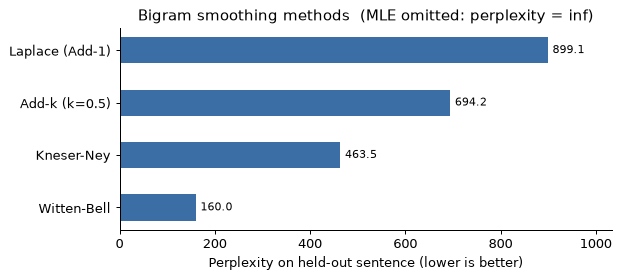

In [7]:
# Activity 5  |  Eman Amjad  |  FA23-BAI-013
train_data_kn, vocab_kn = padded_everygram_pipeline(2, tokenized_corpus)
kn_bigram = KneserNeyInterpolated(2)
kn_bigram.fit(train_data_kn, vocab_kn)
kn_perplexity = kn_bigram.perplexity(held_out_bigrams)

train_data_wb, vocab_wb = padded_everygram_pipeline(2, tokenized_corpus)
wb_bigram = WittenBellInterpolated(2)
wb_bigram.fit(train_data_wb, vocab_wb)
wb_perplexity = wb_bigram.perplexity(held_out_bigrams)

# keep the model objects next to their names so the winner can be picked programmatically
bigram_models = {
    "Unsmoothed (MLE)": mle_bigram,
    "Laplace (Add-1)": laplace_bigram,
    "Add-k (k=0.5)": addk_bigram,
    "Kneser-Ney": kn_bigram,
    "Witten-Bell": wb_bigram,
}
df_results = pd.DataFrame({
    "Method": list(bigram_models),
    "Perplexity": [perplexity, laplace_perplexity, addk_perplexity, kn_perplexity, wb_perplexity],
})
df_results["Finite"] = ~df_results["Perplexity"].apply(math.isinf)
print(df_results.to_string(index=False, formatters={"Perplexity": lambda p: show_pp(p).split()[0]}))

# best = lowest finite perplexity, read from the table (no hardcoded choice)
finite = df_results[df_results["Finite"]]
best_name = finite.loc[finite["Perplexity"].idxmin(), "Method"]
best_model = bigram_models[best_name]
print(f"\nBest performing method (lowest finite perplexity): {best_name}")

fig, ax = plt.subplots(figsize=(7, 3.2), dpi=90)
ax.barh(finite["Method"], finite["Perplexity"], color="#3b6ea5", height=0.5)
for y, p in enumerate(finite["Perplexity"]):
    ax.text(p + 10, y, f"{p:.1f}", va="center", fontsize=9)
ax.invert_yaxis()
ax.set_xlabel("Perplexity on held-out sentence (lower is better)")
ax.set_title("Bigram smoothing methods  (MLE omitted: perplexity = inf)")
ax.spines[["top", "right"]].set_visible(False)
ax.set_xlim(0, finite["Perplexity"].max() * 1.15)
plt.tight_layout()
plt.show()

**Result.** The ranking is MLE (inf) > Laplace (≈899) > Add-0.5 (≈694) > Kneser-Ney (≈463) >
**Witten-Bell (≈160)**, so Witten-Bell is selected as the best method. The two interpolated methods win
because an unseen bigram is not given a flat share of mass; its probability is mixed in from the unigram
distribution, so a word like *fantastic* or *convincing* still gets a sensible estimate after an
unseen context. Witten-Bell beats Kneser-Ney here by almost 3x: its weight on the lower-order model
grows with the number of distinct words seen after a context, and contexts such as *was* are followed
by many different words, so it backs off heavily exactly where this sentence needs it.

One caution from the manual: interpolated models never give zero probability to an in-vocabulary
word, so a low perplexity on one sentence does not prove the model's individual next-word rankings are
sensible. One sentence is also a very small test set.

**Activity 6** — Using the best-performing method from Activity 5, take the partial sentence
"the acting in this film was quite" and score two candidate next words, "disappointing" and
"wonderful", by computing the probability of each completed sentence. Report which candidate the
model prefers and relate this to a keyboard-suggestion feature.

In [8]:
# Activity 6  |  Eman Amjad  |  FA23-BAI-013
print(f"Model used: {best_name}  (chosen from the Activity 5 table)\n")


def get_sentence_prob(sentence, model, n=2):
    tokens = word_tokenize(sentence.lower())
    return sentence_prob(model, list(ngrams(pad_both_ends(tokens, n=n), n)))


base_sentence = "the acting in this film was quite"
candidates = ["disappointing", "wonderful"]
rows = []
for word in candidates:
    rows.append({
        "candidate": word,
        "C(quite, word)": best_model.counts[["quite"]][word],
        "C(word)": best_model.counts[word],
        "C(word, </s>)": best_model.counts[[word]]["</s>"],
        "P(word | quite)": best_model.score(word, ["quite"]),
        "P(</s> | word)": best_model.score("</s>", [word]),
        "P(full sentence)": get_sentence_prob(f"{base_sentence} {word}", best_model),
    })
cand_df = pd.DataFrame(rows)
print(cand_df.to_string(index=False))

preferred = cand_df.loc[cand_df["P(full sentence)"].idxmax(), "candidate"]
print(f"\nThe model prefers: '{preferred}'")

# what a keyboard would actually show after "quite": the top words of P(w | quite)
scores = {w: best_model.score(w, ["quite"]) for w in best_model.vocab
          if w not in ("<s>", "<UNK>")}
top5 = sorted(scores.items(), key=lambda kv: kv[1], reverse=True)[:5]
print("\nTop-5 keyboard suggestions after '... quite':")
for w, p in top5:
    print(f"  {w:12s} {p:.4f}")

Model used: Witten-Bell  (chosen from the Activity 5 table)

    candidate  C(quite, word)  C(word)  C(word, </s>)  P(word | quite)  P(</s> | word)  P(full sentence)
disappointing               0        7              0         0.000234        0.016694      6.477926e-19
    wonderful               0        9              0         0.000301        0.027824      1.388127e-18

The model prefers: 'wonderful'

Top-5 keyboard suggestions after '... quite':
  as           0.0831
  good         0.0409
  so           0.0408
  know         0.0404
  realistic    0.0401


**Answer.** Witten-Bell prefers **wonderful**: its completed sentence scores ≈1.39e-18 against
≈6.48e-19 for *disappointing*, about 2.1 times higher. Neither *(quite, disappointing)* nor
*(quite, wonderful)* occurs in training, and neither word ever ends a training sentence, so both deciding
factors are backed-off estimates. *wonderful* appears 9 times against 7, which gives it the larger
$P(w \mid \text{quite})$ (0.000301 vs 0.000234) and also the larger $P(\text{</s>} \mid w)$.
So the preference reflects word frequency in the corpus, not any judgement about the review's meaning.

A keyboard-suggestion feature does the same scoring at every keystroke: it takes the last one or two
typed words as context, scores the vocabulary with $P(w \mid \text{context})$, and shows the top
1–3 words above the keyboard (like the top-5 list printed above). Real systems use much larger corpora
and personalisation, which is why their suggestions are less generic than this 800-sentence model's.

---
# Home Activities

The home activities use `product_reviews_corpus.txt` and a held-out product-review sentence that is not
in the corpus: **"the battery life of this phone is impressive and the screen looks gorgeous"**.

**Home Activity 1** — On the product_reviews_corpus dataset, fit two smoothing methods of your choice on a
bigram model and report the perplexity of each on the held-out sentence. State which method performed
better and justify the choice using the numbers.

In [9]:
# Home Activity 1  |  Eman Amjad  |  FA23-BAI-013
with open(DATA / "product_reviews_corpus.txt", "r", encoding="utf-8") as f:
    product_corpus = [line.strip().lower() for line in f if line.strip()]
product_tok = [word_tokenize(s) for s in product_corpus]

product_held_out = "the battery life of this phone is impressive and the screen looks gorgeous"
assert product_held_out not in product_corpus
product_held_tok = word_tokenize(product_held_out.lower())
print(f"Training sentences: {len(product_tok)}, tokens: {sum(map(len, product_tok))}")


def fit_lm(model_cls, n, sents, unk_cutoff=1):
    """Fit an nltk.lm model. unk_cutoff=2 maps training words seen once to <UNK>,
    so the model learns real counts for <UNK> and can score unseen words."""
    train, vocab_text = padded_everygram_pipeline(n, sents)
    if unk_cutoff == 1:
        model = model_cls(n)
        model.fit(train, vocab_text)
    else:
        vocab = Vocabulary(flatten(pad_both_ends(s, n=n) for s in sents), unk_cutoff=unk_cutoff)
        model = model_cls(n, vocabulary=vocab)
        model.fit(train)
    return model


def held_grams(tokens, n):
    return list(ngrams(pad_both_ends(tokens, n=n), n))


hb = held_grams(product_held_tok, 2)
methods = {"Kneser-Ney": KneserNeyInterpolated, "Witten-Bell": WittenBellInterpolated}
vocab_setups = {"closed vocab (cutoff 1)": 1, "open vocab, <UNK> trained (cutoff 2)": 2}

home_models, rows = {}, []
for vname, cutoff in vocab_setups.items():
    for mname, cls in methods.items():
        model = fit_lm(cls, 2, product_tok, unk_cutoff=cutoff)
        home_models[(mname, cutoff)] = model
        rows.append({"Method": mname, "Vocabulary": vname, "|V|": len(model.vocab),
                     "Perplexity": model.perplexity(hb)})
ha1 = pd.DataFrame(rows)
print(ha1.to_string(index=False, formatters={"Perplexity": lambda p: show_pp(p).split()[0]}))

finite_ha1 = ha1[~ha1["Perplexity"].apply(math.isinf)]
best_row = finite_ha1.loc[finite_ha1["Perplexity"].idxmin()]
home_best_name = best_row["Method"]
home_cutoff = vocab_setups[best_row["Vocabulary"]]
home_best = home_models[(home_best_name, home_cutoff)]
home_best_cls = methods[home_best_name]
print(f"\nBest home model: {home_best_name} bigram, {best_row['Vocabulary']}, "
      f"perplexity {best_row['Perplexity']:.2f}")

Training sentences: 3944, tokens: 73877


     Method                           Vocabulary  |V| Perplexity
 Kneser-Ney              closed vocab (cutoff 1) 5193        inf
Witten-Bell              closed vocab (cutoff 1) 5193        inf
 Kneser-Ney open vocab, <UNK> trained (cutoff 2) 2841     103.69
Witten-Bell open vocab, <UNK> trained (cutoff 2) 2841      79.01

Best home model: Witten-Bell bigram, open vocab, <UNK> trained (cutoff 2), perplexity 79.01


**Answer.** I compared the two methods that did best in the lab, Kneser-Ney and Witten-Bell. With the
default closed vocabulary **both** return inf: the held-out word *gorgeous* never appears in the product
reviews, it becomes `<UNK>`, and `<UNK>` has zero count at every order, so even the interpolated
models end up multiplying by zero. The standard fix is an open vocabulary: words seen only once in
training are mapped to `<UNK>` (`unk_cutoff=2`), so `<UNK>` gets real counts and a real probability.
With that, Kneser-Ney scores **≈103.7** and Witten-Bell **≈79.0**. Witten-Bell is the better method
on this sentence (about 24% lower perplexity) and is used for the rest of the home activities.

**Home Activity 2** — Build a simple next-word predictor for a review-writing assistant: given the partial
sentence "the camera quality exceeded my", use the best smoothed model to rank the candidate next words
"expectations", "budget" and "screen". Report the ranked probabilities and the first suggestion.

In [10]:
# Home Activity 2  |  Eman Amjad  |  FA23-BAI-013
partial = "the camera quality exceeded my"
context = word_tokenize(partial.lower())
candidates = ["expectations", "budget", "screen"]


def rank_next_words(model, context_tokens, words):
    n = model.order
    ctx = list(context_tokens[-(n - 1):])          # a bigram model only sees the last word
    col = f"P(w | {' '.join(ctx)})"
    rows = []
    for w in words:
        full = held_grams(context_tokens + [w], n)
        rows.append({"candidate": w, col: model.score(w, ctx),
                     "P(completed sentence)": sentence_prob(model, full)})
    df = pd.DataFrame(rows).sort_values(col, ascending=False).reset_index(drop=True)
    df.index = df.index + 1
    return df


print(f"Model: {home_best_name} bigram (open vocabulary)\n")
for w in candidates:
    print(f"  training count of 'my {w}': {home_best.counts[['my']][w]},  count of '{w}': {home_best.counts[w]}")
ranked_bi = rank_next_words(home_best, context, candidates)
print()
print(ranked_bi.to_string(float_format=lambda p: f"{p:.3e}"))
print(f"\nAssistant's first suggestion: '{ranked_bi.iloc[0]['candidate']}'")

Model: Witten-Bell bigram (open vocabulary)

  training count of 'my expectations': 2,  count of 'expectations': 4
  training count of 'my budget': 2,  count of 'budget': 5
  training count of 'my screen': 0,  count of 'screen': 65

      candidate  P(w | my)  P(completed sentence)
1        budget  2.793e-03              8.326e-17
2  expectations  2.789e-03              9.354e-17
3        screen  2.448e-04              1.243e-17

Assistant's first suggestion: 'budget'


**Answer.** The bigram assistant only looks at the last word *my*. Both *my expectations* and *my budget*
occur twice in the training reviews and *my screen* never does, so *screen* is clearly last. The first two
are nearly tied (≈2.79e-3 each); *budget* edges ahead by about 0.1% only because it is slightly more
frequent overall, so the bigram assistant would suggest **budget** first. That is the wrong suggestion for
a sentence about camera quality, and it shows the weakness of a one-word context: the word *exceeded*,
which strongly signals *expectations*, is invisible to a bigram model. (Ranked by the probability of the
whole completed sentence, *expectations* comes first because it ends sentences more often.) Home Activity 3
repeats the ranking with a trigram model.

**Home Activity 3** — Train a bigram and a trigram model (using the chosen smoothing method) on the
product_reviews_corpus. Compute the perplexity of each on the held-out sentence and explain which model
generalises better to this unseen sentence.

In [11]:
# Home Activity 3  |  Eman Amjad  |  FA23-BAI-013
bi = fit_lm(home_best_cls, 2, product_tok, unk_cutoff=home_cutoff)
tri = fit_lm(home_best_cls, 3, product_tok, unk_cutoff=home_cutoff)

pp_bi = bi.perplexity(held_grams(product_held_tok, 2))
pp_tri = tri.perplexity(held_grams(product_held_tok, 3))
seen_tri = sum(tri.counts[[g[0], g[1]]][g[2]] > 0 for g in held_grams(product_held_tok, 3))

print(f"{home_best_name} bigram  perplexity: {pp_bi:.2f}")
print(f"{home_best_name} trigram perplexity: {pp_tri:.2f}")
print(f"Held-out trigrams seen in training: {seen_tri}/{len(held_grams(product_held_tok, 3))}")
print("Better generalisation:", "trigram" if pp_tri < pp_bi else "bigram")

# the next-word ranking from Home Activity 2, now with two words of context
print("\nNext-word ranking with the trigram model:")
ranked_tri = rank_next_words(tri, context, candidates)
print(ranked_tri.to_string(float_format=lambda p: f"{p:.3e}"))

Witten-Bell bigram  perplexity: 79.01
Witten-Bell trigram perplexity: 53.62
Held-out trigrams seen in training: 8/15
Better generalisation: trigram

Next-word ranking with the trigram model:
      candidate  P(w | exceeded my)  P(completed sentence)
1  expectations           5.014e-01              3.960e-15
2        budget           1.396e-03              9.796e-18
3        screen           1.116e-04              1.990e-18


**Answer.** The interpolated Witten-Bell trigram scores **≈53.6** against **≈79.0** for the bigram, so the
trigram generalises better to this sentence. Unsmoothed, the trigram would have been worse (Activity 2),
but interpolation means that when a trigram is unseen the model falls back smoothly on the bigram and
unigram estimates, and when it *is* seen (e.g. *the battery life*, *battery life of*) the longer context
gives a sharper, higher probability. The extra context also fixes the Home Activity 2 problem: with
*exceeded my* as context the trigram model ranks **expectations** first by a wide margin.
With only ~4k training sentences the gain from higher orders will not keep growing; a 4-gram would be
mostly unseen contexts.

**Home Activity 4** — Identify a word in the held-out sentence that does not appear anywhere in the
product_reviews_corpus training data. Compute the probability of the sentence containing this
out-of-vocabulary word under an unsmoothed model and under the best smoothed model, and report both
perplexity values.

In [12]:
# Home Activity 4  |  Eman Amjad  |  FA23-BAI-013
training_words = set(w for s in product_tok for w in s)
oov = [w for w in product_held_tok if w not in training_words]
print("Out-of-vocabulary word(s) in the held-out sentence:", oov)

mle_closed = fit_lm(MLE, 2, product_tok, unk_cutoff=1)
hb = held_grams(product_held_tok, 2)

rows = []
for g in hb:
    if any(w in oov for w in g):
        rows.append({"bigram": g,
                     "MLE": mle_closed.score(g[1], [g[0]]),
                     f"{home_best_name} (open vocab)": home_best.score(g[1], [g[0]])})
print("\nBigrams that touch the OOV word:")
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda p: f"{p:.3e}"))

summary = pd.DataFrame([
    {"Model": "Unsmoothed MLE bigram", "P(sentence)": sentence_prob(mle_closed, hb),
     "Perplexity": mle_closed.perplexity(hb)},
    {"Model": f"{home_best_name} bigram, <UNK> trained", "P(sentence)": sentence_prob(home_best, hb),
     "Perplexity": home_best.perplexity(hb)},
])
print()
print(summary.to_string(index=False, formatters={"P(sentence)": lambda p: f"{p:.3e}",
                                                  "Perplexity": lambda p: show_pp(p).split()[0]}))

Out-of-vocabulary word(s) in the held-out sentence: ['gorgeous']



Bigrams that touch the OOV word:
           bigram       MLE  Witten-Bell (open vocab)
(looks, gorgeous) 0.000e+00                 3.130e-02
 (gorgeous, </s>) 0.000e+00                 1.134e-02

                            Model P(sentence) Perplexity
            Unsmoothed MLE bigram   0.000e+00        inf
Witten-Bell bigram, <UNK> trained   2.706e-27      79.01


**Answer.** The only out-of-vocabulary word is **gorgeous**. Under the unsmoothed MLE bigram both
*(looks, gorgeous)* and *(gorgeous, </s>)* get probability 0 (the word has no counts at all), so the
sentence probability is **0** and the perplexity is **inf**; the unseen bigrams *(is, impressive)* and
*(screen, looks)* would have zeroed it anyway. Under Witten-Bell with a trained `<UNK>` token,
*gorgeous* is scored as `<UNK>`, which has a learned probability from the rare training words, so the
sentence gets a small positive probability and a finite perplexity of **≈79.0**. As Home Activity 1
showed, smoothing alone is not enough for a truly new word in `nltk.lm`; the model also needs an open
vocabulary with an `<UNK>` class that has real training counts.

---

### Lab 05 complete

6 in-lab activities and 4 home activities — submitted by Eman Amjad (FA23-BAI-013).